<a href="https://colab.research.google.com/github/MuhammadSahlanHabibi/Attributing-direct-drivers-to-deforestation-alerts-with-satellite-imagery-and-AI/blob/main/Deforestation_Driver_Attribution_using_Satellite_Indices_%26_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Memulai pemodelan Spatial AI untuk Klasifikasi Deforestasi...

=== HASIL EVALUASI MODEL SPATIAL AI ===
Macro F1-Score : 0.4805

Laporan Klasifikasi Lengkap:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96       186
           1       0.00      0.00      0.00        14

    accuracy                           0.93       200
   macro avg       0.46      0.50      0.48       200
weighted avg       0.86      0.93      0.89       200



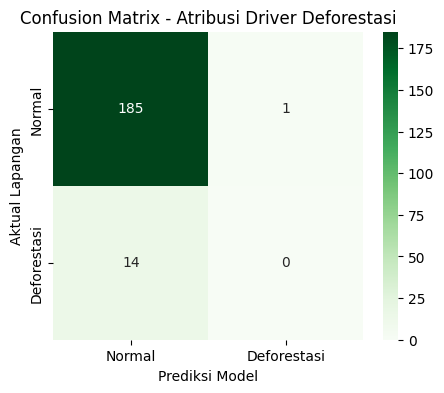

In [4]:
# ==============================================================================
# IMPLEMENTASI SEMINAR 6: SPATIAL AI & DEFORESTATION DRIVER ATTRIBUTION
# Topik: Evaluasi Model Klasifikasi Deforestasi dengan Imbalanced Dataset (F1-Score)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, confusion_matrix

print("Memulai pemodelan Spatial AI untuk Klasifikasi Deforestasi...\n")

# 1. SIMULASI DATASET (Fitur Satelit & Driver Deforestasi)
# Kelas Target: 0 = Perubahan Alami/Lainnya, 1 = Deforestasi akibat Ekspansi Lahan (Minoritas/Imbalanced)
np.random.seed(42)
n_samples = 1000

df_deforest = pd.DataFrame({
    'Indeks_Vegetasi_NDVI': np.random.normal(0.6, 0.15, n_samples),
    'Kerapatan_Kanopi_SAR': np.random.normal(50, 15, n_samples),
    'Jarak_ke_Akses_Jalan': np.random.exponential(scale=5.0, size=n_samples)
})

# Membuat data sangat tidak seimbang (hanya ~5% yang merupakan kejadian deforestasi target)
df_deforest['Target_Deforestasi'] = np.random.choice([0, 1], size=n_samples, p=[0.92, 0.08])

X = df_deforest[['Indeks_Vegetasi_NDVI', 'Kerapatan_Kanopi_SAR', 'Jarak_ke_Akses_Jalan']]
y = df_deforest['Target_Deforestasi']

# 2. DATA SPLITTING
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. TRAINING MODEL DENGAN CLASS WEIGHT (Menangani Imbalanced Data)
clf_spatial = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
clf_spatial.fit(X_train, y_train)

# 4. EVALUASI MODEL (F1-Score & Classification Report)
y_pred = clf_spatial.predict(X_test)

macro_f1 = f1_score(y_test, y_pred, average='macro')
print("=== HASIL EVALUASI MODEL SPATIAL AI ===")
print(f"Macro F1-Score : {macro_f1:.4f}\n")
print("Laporan Klasifikasi Lengkap:")
print(classification_report(y_test, y_pred))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=['Normal', 'Deforestasi'], yticklabels=['Normal', 'Deforestasi'])
plt.title('Confusion Matrix - Atribusi Driver Deforestasi')
plt.xlabel('Prediksi Model')
plt.ylabel('Aktual Lapangan')
plt.show()